# 3. Preprocesamiento

En este capítulo definimos las transformaciones que convierten las 24 variables categóricas en la entrada numérica de los modelos. La lógica es la misma en scikit-learn (`src/features.py`) y en PySpark (`src/spark_models.py`), y todas las transformaciones se ajustan solo con la muestra de entrenamiento. La estrategia de codificación de las variables de alta cardinalidad es un factor experimental: la pregunta P2 compara cinco estrategias.

| § | Paso | Ajuste |
|---|---|---|
| 3.1 | Agrupación de categorías raras en `__RARE__` | Conteos en entrenamiento |
| 3.2 | Codificación: hashing $2^{12}$, $2^{14}$, $2^{16}$ y frecuencia | Vocabulario y conteos de entrenamiento |
| 3.3 | Target encoding fuera de pliegue | Validación cruzada dentro de entrenamiento |
| 3.4 | $\log(1 + n)$ y `StandardScaler` en las estrategias densas | Media y desviación de entrenamiento |
| 3.5 | Cruces de variables (ablación) | Igual que las variables originales |
| 3.6 | Equivalencia entre scikit-learn y PySpark | Verificación empírica |
| 3.7 | Controles contra la fuga de información | Lista de verificación |

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src import config as C
from src import plots as P
from src import report as R
from src.persist import load_json

P.setup()
C.ensure_dirs()
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 90)
print("Resultados:", C.RESULTS.relative_to(C.ROOT), "| prueba de humo:", C.SMOKE)

import polars as pl
import scipy.sparse as sp
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from src import data as D, features as F

grupos = C.column_groups()
tr = D.load_train(C.SIZES[C.MAIN_SIZE])
va = D.load_val()
te = D.load_test()
ytr, yva = D.y_of(tr), D.y_of(va)
print(f"Entrenamiento: {R.num(tr.height)} filas | validación: {R.num(va.height)} | prueba: {R.num(te.height)}")

Resultados: results | prueba de humo: False


Entrenamiento: 1 000 000 filas | validación: 1 000 000 | prueba: 4 218 938


## 3.1 Agrupación de categorías raras

Una categoría con pocas apariciones aporta un parámetro que el modelo estima con mucho ruido. Reemplazamos por `__RARE__` las categorías con menos de 10 apariciones en la muestra de entrenamiento. El mismo vocabulario se aplica después a validación y prueba, de modo que una categoría nueva, que no existía en entrenamiento, también se convierte en `__RARE__`.

La tabla muestra, para cada variable, la fracción de filas que pasan a `__RARE__` en cada partición. La diferencia entre entrenamiento y prueba mide cuántas categorías de prueba el modelo no vio.

,device_ip,C14,C17,C21,device_id,C19,device_model,app_id,site_id,site_domain,...,banner_pos,C1,C16,C15,device_conn_type,device_type,C18,hora,dia_semana,franja
vocabulario,9304.00,1346.00,340.00,52.00,169.00,58.00,2643.00,919.00,1195.00,989.00,...,7.0,7.0,9.0,8.0,4.0,4.0,4.0,24.0,7.0,4.0
% __RARE__ entrenamiento,73.59,0.20,0.01,0.00,17.00,0.00,0.82,0.56,0.46,0.52,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
% __RARE__ validación,78.22,23.87,23.35,1.30,20.40,1.55,1.15,0.80,0.56,0.57,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
% __RARE__ prueba,84.05,36.47,33.62,19.25,15.03,10.44,1.20,1.16,0.64,0.54,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


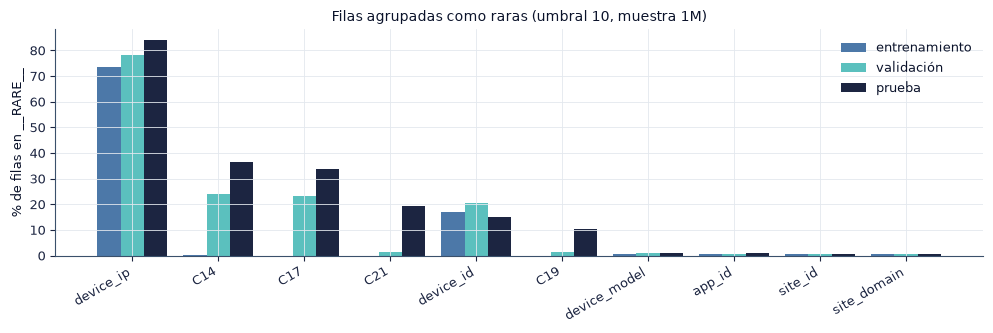

In [2]:
rg = F.RareGrouper(C.CAT_COLS).fit(tr)
rare = pd.DataFrame({"vocabulario": {c: len(rg.vocab_[c]) for c in C.CAT_COLS},
                     "entrenamiento": rg.rare_share(tr), "validación": rg.rare_share(va), "prueba": rg.rare_share(te)})
rare = rare.sort_values("prueba", ascending=False)
display((rare.assign(**{k: (100 * rare[k]).round(2) for k in ["entrenamiento", "validación", "prueba"]}))
        .rename(columns={"entrenamiento": "% __RARE__ entrenamiento", "validación": "% __RARE__ validación", "prueba": "% __RARE__ prueba"}).T)

fig, ax = plt.subplots(figsize=(10, 3.4))
top = rare.head(10)
x = np.arange(len(top)); w = 0.27
for k, (col, cc) in enumerate([("entrenamiento", C.BAR), ("validación", "#5BC0BE"), ("prueba", "#1C2541")]):
    ax.bar(x + (k - 1) * w, 100 * top[col], w, color=cc, label=col)
ax.set_xticks(x, top.index, rotation=30, ha="right"); ax.set_ylabel("% de filas en __RARE__")
ax.set_title(f"Filas agrupadas como raras (umbral {C.RARE_MIN_COUNT}, muestra {C.MAIN_SIZE})"); ax.legend()
fig.tight_layout(); P.save(fig, "3_1_raras"); plt.show()

In [3]:
v = rare.iloc[0]
R.findings(
    f"`{rare.index[0]}` es la variable con más filas agrupadas: {R.pct(v['entrenamiento'])} en entrenamiento y {R.pct(v['prueba'])} en prueba. "
    f"En promedio, la fracción de filas raras sube de {R.pct(rare['entrenamiento'].mean())} en entrenamiento a {R.pct(rare['prueba'].mean())} "
    "en prueba, porque la prueba contiene categorías que no aparecen en la muestra de entrenamiento.",
    {"Preprocesamiento": "el vocabulario se recalcula con cada muestra de entrenamiento; con muestras más grandes, más categorías superan el umbral.",
     "Modelado": "para el modelo, `__RARE__` es una categoría más; su parámetro resume el comportamiento de las categorías poco frecuentes y de las nuevas.",
     "Riesgos": "la proporción de categorías nuevas en prueba crece con la distancia temporal al entrenamiento; es una fuente de pérdida de desempeño que ninguna codificación elimina."})

### Hallazgos y decisiones

`device_ip` es la variable con más filas agrupadas: 73.6 % en entrenamiento y 84.1 % en prueba. En promedio, la fracción de filas raras sube de 3.9 % en entrenamiento a 8.4 % en prueba, porque la prueba contiene categorías que no aparecen en la muestra de entrenamiento.

- **Preprocesamiento:** el vocabulario se recalcula con cada muestra de entrenamiento; con muestras más grandes, más categorías superan el umbral.
- **Modelado:** para el modelo, `__RARE__` es una categoría más; su parámetro resume el comportamiento de las categorías poco frecuentes y de las nuevas.
- **Riesgos:** la proporción de categorías nuevas en prueba crece con la distancia temporal al entrenamiento; es una fuente de pérdida de desempeño que ninguna codificación elimina.


## 3.2 Estrategias de codificación

**Hashing.** Cada par "variable=valor" se asigna a la columna $h(\text{"variable=valor"}) \bmod d$ con valor 1, y las colisiones se suman. La matriz es dispersa: cada fila tiene a lo sumo 24 entradas distintas de cero. El hashing no necesita guardar un vocabulario para codificar y su memoria no depende del número de categorías (Weinberger et al., 2009). Su costo son las colisiones: dos categorías distintas comparten columna y el modelo no puede distinguirlas.

**Frecuencia.** Cada variable de alta cardinalidad se reemplaza por $\log(1 + n)$, donde $n$ es el número de apariciones de su categoría en entrenamiento, estandarizado. Las variables de baja cardinalidad reciben one-hot. La representación es densa y pequeña, pero dos categorías con el mismo conteo quedan iguales.

**Target encoding.** Cada categoría se reemplaza por una estimación suavizada de su CTR (sección 3.3).

La tabla resume cada estrategia en la muestra principal: dimensión, número medio de entradas no nulas por fila, memoria de la matriz de entrenamiento y tiempo de ajuste del preprocesamiento.

In [4]:
rows = []
mats = {}
for enc in C.ENCODINGS:
    rec = {}
    prep = F.CTRPreprocessor(enc, groups=grupos)
    from src import bench
    with bench.stage(rec, "prep", rows=tr.height):
        X = prep.fit_transform(tr, ytr)
    nnz = X.nnz / X.shape[0] if sp.issparse(X) else float(np.count_nonzero(X) / X.shape[0])
    rows.append({"codificación": C.ENCODING_LABELS[enc], "tipo": "dispersa" if sp.issparse(X) else "densa",
                 "dimensión": X.shape[1], "no nulos por fila": round(nnz, 2), "memoria (MB)": round(F.matrix_bytes(X) / 1024**2, 1),
                 "ajuste (s)": round(rec["prep_s"], 2)})
    mats[enc] = (prep, X)
enc_tab = pd.DataFrame(rows).set_index("codificación")
display(enc_tab)

,tipo,dimensión,no nulos por fila,memoria (MB),ajuste (s)
codificación,,,,,
Hashing 2^12,dispersa,4096,23.98,186.8,0.86
Hashing 2^14,dispersa,16384,23.99,186.9,1.05
Hashing 2^16,dispersa,65536,24.00,186.9,0.89
Frecuencia,densa,242,24.00,923.2,5.09
Target encoding OOF,densa,242,24.00,923.2,8.53


**Colisiones del hashing.** Contamos los pares "variable=valor" distintos que hay en la muestra de entrenamiento después de agrupar las raras, y cuántos de ellos comparten columna con otro par para cada dimensión $d$. Si hay $V$ pares distintos y la función hash reparte de forma uniforme, el número esperado de columnas ocupadas es $d\,\big(1 - (1 - 1/d)^{V}\big)$.

In [5]:
from src.features import HASH_SEED
g = rg.transform(tr.select(C.CAT_COLS))
tokens = pl.concat([g.select(pl.concat_str([pl.lit(f"{c}="), pl.col(c)]).alias("t")).unique() for c in C.CAT_COLS])["t"]
V = len(tokens)
col_rows = []
for enc, d in C.HASH_DIMS.items():
    idx = (tokens.hash(seed=HASH_SEED) % d).to_numpy()
    u, cnt = np.unique(idx, return_counts=True)
    shared = cnt[cnt > 1].sum()
    X = mats[enc][1]
    col_rows.append({"codificación": C.ENCODING_LABELS[enc], "d": d, "pares distintos V": V, "columnas ocupadas": len(u),
                     "esperadas (uniforme)": round(d * (1 - (1 - 1 / d) ** V)), "% de pares que comparten columna": round(100 * shared / V, 1),
                     "% de filas con colisión interna": round(100 * float(np.mean(np.diff(X.indptr) < len(C.CAT_COLS))), 2)})
col_tab = pd.DataFrame(col_rows).set_index("codificación")
display(col_tab)

,d,pares distintos V,columnas ocupadas,esperadas (uniforme),% de pares que comparten columna,% de filas con colisión interna
codificación,,,,,,
Hashing 2^12,4096,17371,4040,4037,98.4,1.80
Hashing 2^14,16384,17371,10637,10709,65.6,0.68
Hashing 2^16,65536,17371,15212,15260,23.7,0.44


In [6]:
h12, h16 = col_tab.iloc[0], col_tab.iloc[-1]
mem = enc_tab["memoria (MB)"]
R.findings(
    f"La muestra de entrenamiento tiene {R.num(V)} pares variable=valor distintos. Con $d = 2^{{12}}$ comparten columna "
    f"{h12['% de pares que comparten columna']:.1f} % de los pares; con $d = 2^{{16}}$, {h16['% de pares que comparten columna']:.1f} %. "
    f"Las tres matrices de hashing ocupan casi la misma memoria ({mem.iloc[0]:.1f} a {mem.iloc[2]:.1f} MB), porque una matriz dispersa "
    f"solo almacena las entradas no nulas; la de frecuencia ocupa {mem.loc[C.ENCODING_LABELS['freq']]:.1f} MB por ser densa, con "
    f"{enc_tab.loc[C.ENCODING_LABELS['freq'], 'dimensión']} columnas.",
    {"Preprocesamiento": "el hashing es la única estrategia cuya memoria no crece con la cardinalidad; la de frecuencia crece con el número de categorías de baja cardinalidad, por el one-hot.",
     "Modelado": "en el MLP, la primera capa tiene $d \\times h$ pesos: con $d = 2^{16}$ y 256 neuronas son 16.8 millones de parámetros, aunque cada fila active solo 24 columnas.",
     "Riesgos": "la memoria de la matriz no es la memoria del entrenamiento: el MLP denso de Spark convierte la entrada dispersa en bloques densos (capítulo 5)."})

### Hallazgos y decisiones

La muestra de entrenamiento tiene 17 371 pares variable=valor distintos. Con $d = 2^{12}$ comparten columna 98.4 % de los pares; con $d = 2^{16}$, 23.7 %. Las tres matrices de hashing ocupan casi la misma memoria (186.8 a 186.9 MB), porque una matriz dispersa solo almacena las entradas no nulas; la de frecuencia ocupa 923.2 MB por ser densa, con 242 columnas.

- **Preprocesamiento:** el hashing es la única estrategia cuya memoria no crece con la cardinalidad; la de frecuencia crece con el número de categorías de baja cardinalidad, por el one-hot.
- **Modelado:** en el MLP, la primera capa tiene $d \times h$ pesos: con $d = 2^{16}$ y 256 neuronas son 16.8 millones de parámetros, aunque cada fila active solo 24 columnas.
- **Riesgos:** la memoria de la matriz no es la memoria del entrenamiento: el MLP denso de Spark convierte la entrada dispersa en bloques densos (capítulo 5).


## 3.3 Target encoding fuera de pliegue

El *target encoding* reemplaza la categoría $c$ por una media suavizada del objetivo (Micci-Barreca, 2001):

$$\text{TE}(c) = \frac{n_c\, \bar y_c + m\, \bar y}{n_c + m},$$

donde $n_c$ y $\bar y_c$ son el número de impresiones y el CTR de la categoría, $\bar y$ es el CTR global y $m$ controla la contracción hacia la media; `TargetEncoder` de scikit-learn estima $m$ por variable.

Si una fila de entrenamiento se codifica con una media que incluye su propia etiqueta, la variable codificada contiene información del objetivo: es fuga de información. La codificación **fuera de pliegue** (*out-of-fold*) parte el entrenamiento en $K = 5$ pliegues y codifica cada pliegue con las medias de los otros cuatro. Como las filas están ordenadas en el tiempo, usamos pliegues contiguos sin barajar. Validación y prueba se codifican con las medias de todo el entrenamiento.

Comparamos ambas versiones con una regresión logística entrenada solo con las variables codificadas. Esta implementación existe solo en scikit-learn: PySpark no trae un *target encoding* fuera de pliegue, y programarlo con uniones por pliegue cambiaría la lógica que comparamos entre entornos.

In [7]:
from sklearn.model_selection import KFold
from sklearn.preprocessing import TargetEncoder
hi = [c for c in C.CAT_COLS if c not in grupos["baja"]]
gtr = rg.transform(tr.select(C.CAT_COLS)).select(hi).to_pandas()
gva = rg.transform(va.select(C.CAT_COLS)).select(hi).to_pandas()
te_in = TargetEncoder(target_type="binary").fit(gtr, ytr)
Xin_tr, Xin_va = te_in.transform(gtr), te_in.transform(gva)               # ingenua: incluye la propia etiqueta
te_oof = TargetEncoder(target_type="binary", cv=KFold(C.TARGET_ENCODER_CV, shuffle=False))
Xoof_tr = te_oof.fit_transform(gtr, ytr)                                   # fuera de pliegue
Xoof_va = te_oof.transform(gva)
res = []
for name, a, b in [("ingenua (en la muestra)", Xin_tr, Xin_va), ("fuera de pliegue", Xoof_tr, Xoof_va)]:
    lr = LogisticRegression(max_iter=500).fit(a, ytr)
    res.append({"target encoding": name, "AUC entrenamiento": roc_auc_score(ytr, lr.predict_proba(a)[:, 1]),
                "AUC validación": roc_auc_score(yva, lr.predict_proba(b)[:, 1])})
te_tab = pd.DataFrame(res).set_index("target encoding")
te_tab["brecha"] = te_tab["AUC entrenamiento"] - te_tab["AUC validación"]
display(te_tab.round(4))

,AUC entrenamiento,AUC validación,brecha
target encoding,,,
ingenua (en la muestra),0.7404,0.7230,0.0174
fuera de pliegue,0.7212,0.7263,-0.0052


In [8]:
ing, oof = te_tab.iloc[0], te_tab.iloc[1]
R.findings(
    f"Con la codificación ingenua, la regresión logística alcanza un AUC de {ing['AUC entrenamiento']:.4f} en entrenamiento y "
    f"{ing['AUC validación']:.4f} en validación (brecha de {ing['brecha']:.4f}). Fuera de pliegue, la brecha es {oof['brecha']:.4f}. "
    + ("La diferencia entre las dos brechas es la fuga de información: la versión ingenua aprende de su propia etiqueta y su desempeño en entrenamiento no se sostiene fuera de él."
       if ing["brecha"] > oof["brecha"] else
       "En esta muestra las dos brechas son similares, porque la contracción del codificador limita la fuga en las categorías pequeñas; mantenemos la versión fuera de pliegue como protocolo."),
    {"Preprocesamiento": "usamos solo la versión fuera de pliegue, con pliegues contiguos en el tiempo.",
     "Modelado": "la parada temprana y la búsqueda de hiperparámetros ven la codificación fuera de pliegue, la misma que se aplica a validación y prueba.",
     "Riesgos": "el target encoding es la única estrategia que usa la etiqueta para construir la entrada; por eso es también la más expuesta a la deriva del CTR entre días."})

### Hallazgos y decisiones

Con la codificación ingenua, la regresión logística alcanza un AUC de 0.7404 en entrenamiento y 0.7230 en validación (brecha de 0.0174). Fuera de pliegue, la brecha es -0.0052. La diferencia entre las dos brechas es la fuga de información: la versión ingenua aprende de su propia etiqueta y su desempeño en entrenamiento no se sostiene fuera de él.

- **Preprocesamiento:** usamos solo la versión fuera de pliegue, con pliegues contiguos en el tiempo.
- **Modelado:** la parada temprana y la búsqueda de hiperparámetros ven la codificación fuera de pliegue, la misma que se aplica a validación y prueba.
- **Riesgos:** el target encoding es la única estrategia que usa la etiqueta para construir la entrada; por eso es también la más expuesta a la deriva del CTR entre días.


## 3.4 Transformación logarítmica y escalado

En las estrategias densas, la parte numérica de la entrada (frecuencias o medias del objetivo) se estandariza con la media $\mu_j$ y la desviación $\sigma_j$ de entrenamiento:

$$z_j = \frac{v_j - \mu_j}{\sigma_j}, \qquad v_j = \log(1 + n_j) \text{ (frecuencia) o } v_j = \text{TE}_j \text{ (target encoding)}.$$

Las columnas one-hot no se escalan. En PySpark, `StandardScaler(withMean=True, withStd=True)` actúa solo sobre el vector numérico, y después `VectorAssembler` lo une con los vectores one-hot. Las variables de hashing no se escalan en ninguno de los dos entornos: todas valen 0, 1 o un entero pequeño cuando hay colisión.

## 3.5 Cruces de variables

Un cruce crea una variable nueva con la concatenación de dos variables, por ejemplo `site_id|device_type`. Permite que un modelo lineal capture una interacción que de otra forma no puede representar. Evaluamos dos cruces, `site_id × device_type` y `app_id × device_type`, como ablación del MLP con hashing (capítulo 9): si el MLP ya aprende esas interacciones en su capa oculta, los cruces no deberían mejorar su desempeño.

In [9]:
xt = F.add_crosses(tr.select(C.CAT_COLS))
rgx = F.RareGrouper(F.cross_names()).fit(xt)
display(pd.DataFrame({"categorías distintas": {c: xt[c].n_unique() for c in F.cross_names()},
                      "vocabulario (≥ umbral)": {c: len(rgx.vocab_[c]) for c in F.cross_names()},
                      "% filas a __RARE__": {c: round(100 * v, 2) for c, v in rgx.rare_share(xt).items()}}))

,categorías distintas,vocabulario (≥ umbral),% filas a __RARE__
site_id_x_device_type,2641,1198,0.46
app_id_x_device_type,3331,944,0.60


## 3.6 Equivalencia entre scikit-learn y PySpark

La guía del proyecto pide la misma lógica de preprocesamiento en ambos entornos. La tabla muestra la correspondencia entre componentes.

| Paso | scikit-learn (`src/features.py`) | PySpark (`src/spark_models.py`) |
|---|---|---|
| Lectura | `polars.scan_parquet` con filtro por día y por $u$ | `spark.read.parquet` con el mismo filtro |
| Categorías raras | Conteo con `group_by` y reemplazo con `is_in` | `groupBy().count()` y unión con difusión (*broadcast join*) |
| Hashing | `hash("variable=valor") mod d` en Polars, matriz CSR | `FeatureHasher` (MurmurHash3 de "variable=valor") |
| Frecuencia | `log1p(n)` y estandarización | Unión con la tabla de conteos, `log1p`, `StandardScaler` |
| Baja cardinalidad | One-hot | `StringIndexer` + `OneHotEncoder` |
| Ensamblado | `numpy.hstack` | `VectorAssembler` |
| Target encoding | `TargetEncoder` fuera de pliegue | No disponible (sección 3.3) |

Las dos funciones hash son distintas (la de Polars y MurmurHash3), por lo que las colisiones ocurren entre pares diferentes, pero su número esperado es el mismo para una dimensión dada. Verificamos que ambos entornos construyen el mismo vocabulario de categorías frecuentes sobre la misma muestra.

In [10]:
from src import spark_models as SP
n_chk = min(C.SPARK_TUNE_ROWS, D.window_rows(C.TRAIN_DAYS))
spark = SP.get_spark(C.SPARK_CORES_MAIN)
s_tr = SP.read_window(spark, C.TRAIN_DAYS, n_chk).cache()
sprep = SP.SparkPrep("hash", dim=C.SPARK_HASH_DIM).fit(s_tr)
p_tr = D.load_train(n_chk)
p_rg = F.RareGrouper(C.CAT_COLS).fit(p_tr)
chk = pd.DataFrame({"filas (Polars)": p_tr.height, "filas (Spark)": s_tr.count(),
                    "vocabulario Polars": {c: len(p_rg.vocab_[c]) for c in C.CAT_COLS},
                    "vocabulario Spark": {c: sprep.keep_[c].count() for c in C.CAT_COLS}})
chk["iguales"] = chk["vocabulario Polars"] == chk["vocabulario Spark"]
Xs = sprep.transform(s_tr).select("features").first()["features"]
display(chk.T)
print(f"Dimensión de FeatureHasher: {Xs.size} | entradas no nulas de la primera fila: {Xs.numNonzeros()}")
s_tr.unpersist(); SP.stop_spark()

,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,app_category,device_id,device_ip,...,C15,C16,C17,C18,C19,C20,C21,hora,dia_semana,franja
filas (Polars),20000,20000,20000,20000,20000,20000,20000,20000,20000,20000,...,20000,20000,20000,20000,20000,20000,20000,20000,20000,20000
filas (Spark),20000,20000,20000,20000,20000,20000,20000,20000,20000,20000,...,20000,20000,20000,20000,20000,20000,20000,20000,20000,20000
vocabulario Polars,6,4,126,105,11,87,21,10,2,39,...,4,5,177,4,45,73,41,24,7,4
vocabulario Spark,6,4,126,105,11,87,21,10,2,39,...,4,5,177,4,45,73,41,24,7,4
iguales,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True


Dimensión de FeatureHasher: 4096 | entradas no nulas de la primera fila: 24


In [11]:
ok = bool(chk["iguales"].all())
R.findings(
    ("Los dos entornos leen las mismas filas y construyen el mismo vocabulario de categorías frecuentes en las 24 variables."
     if ok else f"El vocabulario difiere en {int((~chk['iguales']).sum())} variables; revisamos el filtro por $u$ antes de continuar."),
    {"Preprocesamiento": "la clave $u$ garantiza que ambos entornos entrenen con las mismas filas; el umbral de raras se cuenta igual.",
     "Modelado": "las diferencias de desempeño entre entornos provienen del modelo y del optimizador, no de los datos de entrada.",
     "Riesgos": "la función hash distinta hace que las colisiones no coincidan fila por fila; el efecto esperado es pequeño y se refleja en la variación entre entornos."})

### Hallazgos y decisiones

Los dos entornos leen las mismas filas y construyen el mismo vocabulario de categorías frecuentes en las 24 variables.

- **Preprocesamiento:** la clave $u$ garantiza que ambos entornos entrenen con las mismas filas; el umbral de raras se cuenta igual.
- **Modelado:** las diferencias de desempeño entre entornos provienen del modelo y del optimizador, no de los datos de entrada.
- **Riesgos:** la función hash distinta hace que las colisiones no coincidan fila por fila; el efecto esperado es pequeño y se refleja en la variación entre entornos.


## 3.7 Controles contra la fuga de información

| Riesgo | Control |
|---|---|
| Ver el futuro al entrenar | Partición temporal: entrenamiento días 21–28, validación 29, prueba 30 |
| Ajustar transformaciones con datos de evaluación | Vocabulario de raras, conteos, codificadores y escaladores se ajustan con la muestra de entrenamiento y solo se aplican a validación y prueba |
| Usar la etiqueta propia en la entrada | Target encoding fuera de pliegue, con pliegues contiguos |
| Elegir decisiones con la prueba | Hiperparámetros, umbral de decisión y mejor codificación se eligen en el día 29 |
| Cambios en el conjunto de prueba | Huella SHA-256 del Parquet del día 30 en el manifiesto; el código la verifica antes de cargarlo |
| Filas distintas entre entornos | Clave de muestreo $u$ común y orden (hora, $u$) idéntico en ambos entornos |
| Consultar la etiqueta de prueba en el EDA | El EDA usa del día 30 solo las variables de entrada (PSI) |